In [1]:
import numpy as np
import xarray as xr
import pandas as pd
from scipy import signal
from scipy.ndimage import center_of_mass
from scipy.signal import hilbert, correlate
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

In [2]:
def bandpass_for_propagation(ssta, dt_months=1, 
                              low_period=3,   # 最短周期（月）
                              high_period=7*12): # 最长周期（月）
    nt, nx = ssta.shape
    
    # 采样频率（周期/月）
    fs = 1.0 / dt_months
    
    # 转换为频率
    low_freq = 1.0 / high_period   # 低频截止
    high_freq = 1.0 / low_period   # 高频截止
    
    # 对每个经度点做带通滤波
    ssta_filtered = np.zeros_like(ssta)
    
    for i in range(nx):
        # Butterworth带通滤波
        sos = signal.butter(4, [low_freq, high_freq], 
                           btype='band', fs=fs, output='sos')
        ssta_filtered[:, i] = signal.sosfiltfilt(sos, ssta[:, i])
    
    return ssta_filtered

In [3]:
xr.open_dataset(r'C:\Users\jiuwe\study\data\SST\HadISST_sst.nc')

<xarray.Dataset>
Dimensions:    (time: 1877, nv: 2, latitude: 180, longitude: 360)
Coordinates:
  * time       (time) datetime64[ns] 1870-01-16T11:59:59.505615234 ... 2026-0...
  * latitude   (latitude) float32 89.5 88.5 87.5 86.5 ... -87.5 -88.5 -89.5
  * longitude  (longitude) float32 -179.5 -178.5 -177.5 ... 177.5 178.5 179.5
Dimensions without coordinates: nv
Data variables:
    time_bnds  (time, nv) float32 ...
    sst        (time, latitude, longitude) float32 ...
Attributes:
    Title:                      Monthly version of HadISST sea surface temper...
    description:                HadISST 1.1 monthly average sea surface tempe...
    institution:                Met Office Hadley Centre
    source:                     HadISST
    reference:                  Rayner, N. A., Parker, D. E., Horton, E. B., ...
    Conventions:                CF-1.0
    history:                    3/7/2026 converted to netcdf from pp format
    supplementary_information:  Updates and supplementary information will be...
    comment:                    Data restrictions: for academic research use ...

In [4]:
lat = np.arange(-90, 91)
lon = np.arange(0, 361)
ds_sst = xr.open_dataset(r'C:\Users\jiuwe\study\data\SST\HadISST_sst.nc').rename({'latitude':'lat', 'longitude':'lon'})
sst_org = ds_sst.sst.loc['1870':'2025']
s1 = sst_org.loc[:, :, -180:0]
s2 = sst_org.loc[:, :, -0:180]
s1 = s1.assign_coords(lon=s1.lon.values+360)
sst = xr.concat([s2, s1], dim='lon')
# sst.assign_coords(time=pd.date_range('1870-01-01', '2025-12-01', freq='MS')).interp(lat=lat, lon=lon).to_netcdf('./data/sst.nc')
sst_cli = sst.loc['1991':'2020']
sst_cli = sst_cli.groupby(sst_cli.time.dt.month).mean()
sst_ano = sst.groupby(sst.time.dt.month) - sst_cli
lat = np.arange(-90, 91)
lon = np.arange(0, 361)
sst_ano.assign_coords(time=pd.date_range('1870-01-01', '2025-12-01', freq='MS')).interp(lat=lat, lon=lon).to_netcdf('./data/ssta.nc')

In [10]:
sst = xr.open_dataset('sst.nc').sel(lon=slice(120, 270)).sst
sst_cli = sst.loc['1991':'2020']
sst_cli = sst_cli.groupby(sst_cli.time.dt.month).mean()
sst_ano = sst.groupby(sst.time.dt.month) - sst_cli
sst_ano = sst_ano.loc['1950':'2024']
time = sst_ano.time
lon = sst_ano.lon
# sst_an = bandpass_for_propagation(sst_ano.loc[:, 5:-5, :].mean(dim='lat'))
# sst_an = xr.DataArray(sst_an, coords={'time':time, 'lon':lon})
sst_an = sst_ano.loc[:, 5:-5, :].mean(dim='lat')
nino = sst_ano.loc[:, 5:-5, 120:240].mean(dim=['lat', 'lon']).rolling(time=3, center=True, min_periods=1).mean()
nt = len(time)


In [219]:
t = 0
start = 0
end = 0
dev = nino.copy()
dev[:] = np.nan
events = []
while t < nt-1:
    if nino[t] <= 0 and nino[t+1] > 0:
        zero = t
    if nino[t] <= 0.5 and nino[t+1] > 0.5:
        start = t
    if nino[t] >= 0.5 and nino[t+1] < 0.5:
        end = t
    if end > start:
        max_loc = np.argmax(nino[zero:end+1].values)
        dev[zero-1:zero+max_loc+2] = nino[zero-1:zero+max_loc+2]
        events.append((zero-1, zero+max_loc+2))
        print(time[zero].values, time[zero+max_loc].values, end-start+1)
        end = start
    t += 1
events = np.array(events)

1951-05-16T12:00:00.000000000 1951-09-16T00:00:00.000000000 6
1957-02-15T00:00:00.000000000 1958-01-16T12:00:00.000000000 10
1963-05-16T12:00:00.000000000 1963-11-16T00:00:00.000000000 8
1965-04-16T00:00:00.000000000 1965-11-16T00:00:00.000000000 10
1968-06-16T00:00:00.000000000 1969-01-16T12:00:00.000000000 6
1968-06-16T00:00:00.000000000 1969-01-16T12:00:00.000000000 6
1972-03-16T12:00:00.000000000 1972-11-16T00:00:00.000000000 9
1976-06-16T00:00:00.000000000 1976-12-16T12:00:00.000000000 7
1977-05-16T12:00:00.000000000 1977-11-16T00:00:00.000000000 5
1982-03-16T12:00:00.000000000 1983-01-16T12:00:00.000000000 14
1986-06-16T00:00:00.000000000 1987-09-16T00:00:00.000000000 18
1989-12-16T12:00:00.000000000 1992-01-16T12:00:00.000000000 10
1992-12-16T12:00:00.000000000 1993-05-16T12:00:00.000000000 5
1994-04-16T00:00:00.000000000 1994-12-16T12:00:00.000000000 7
1997-03-16T12:00:00.000000000 1997-12-16T12:00:00.000000000 13
2002-02-15T00:00:00.000000000 2002-11-16T00:00:00.000000000 9
20

In [239]:
start_date = pd.to_datetime(time[events[:, 0]].values)
end_date = pd.to_datetime(time[events[:, 1]].values)
El_Nino = []
for i in range(events.shape[0]):
    year0 = start_date[i].year
    year1 = end_date[i].year
    month0 = start_date[i].month
    month1 = end_date[i].month
    
    if month1 > 9:
        month1_ = 3
        year1_ = year1 + 1
    elif month1 < 4:
        month1_ = 3
        year1_ = year1
    else:
        continue
    month0_ = 4
    year0_ = year1_ - 1
    # print(year0, month0, year1, month1)
    # print(year0_, month0_, year1_, month1_)
    # print('-------')
    El_Nino.append([f'{year0_}-{month0_:02d}', f'{year1_}-{month1_:02d}'])
        
El_Nino = np.array(El_Nino, dtype='datetime64[M]')

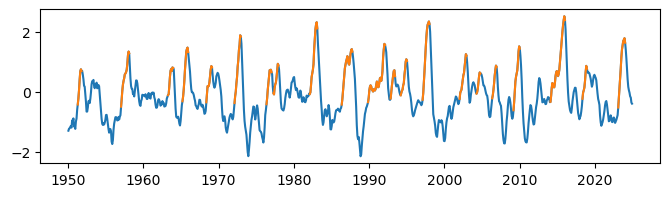

In [101]:
fig, ax = plt.subplots(figsize=(8, 2))
ax.plot(time, nino)
ax.plot(time, dev)


In [7]:
tt = 12
start = events[tt][0]
end = events[tt][1]
sst_a = sst_an[start:end]
ssta_pos = sst_a.where(sst_a>=0.6)
# ssta = sst_a - sst_a.mean(dim='lon')
# ssta = ssta.where(sst_a>=0, 0)
print(time[start].values, time[end].values)

NameError: name 'events' is not defined

In [13]:
start = '1996-10'
end = '1997-12'
sst_a = sst_an.loc[start:end]


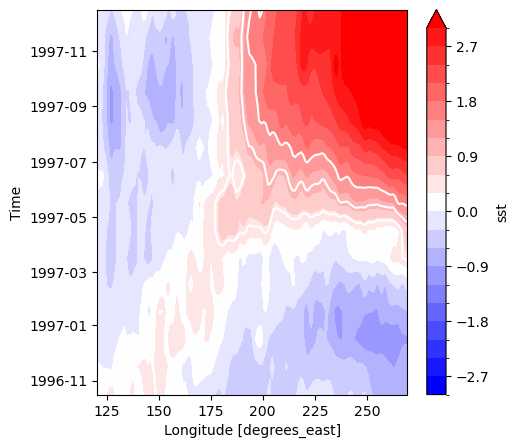

In [14]:
fig, ax = plt.subplots(figsize=(5, 5))
sst_a.plot.contourf(levels=np.linspace(-3, 3, 21), cmap='bwr', ax=ax)
sst_a.plot.contour(levels=[0.5, 1, 1.5], cmap='w', ax=ax)

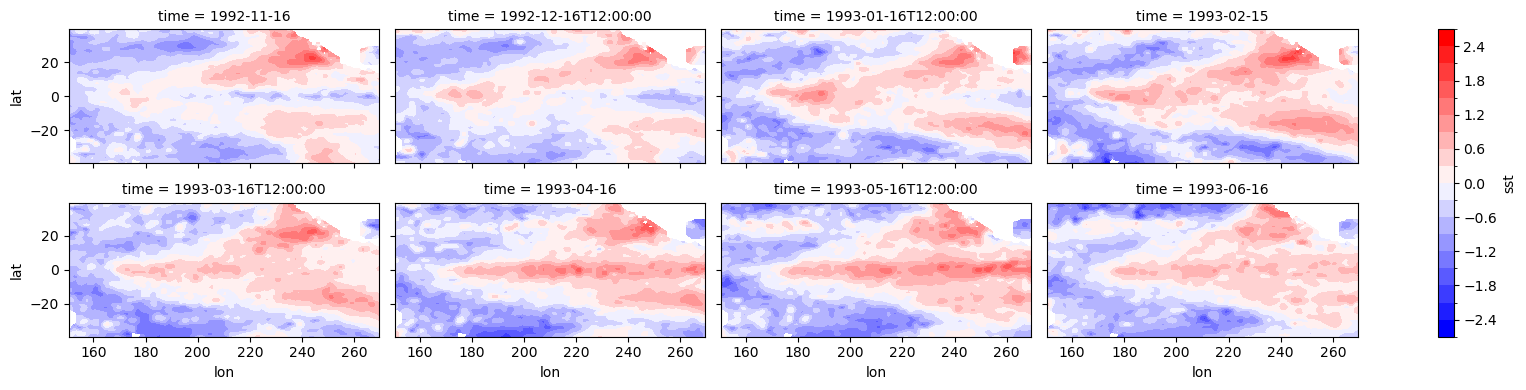

In [213]:
sst_ano[start:end].plot.contourf(col='time', col_wrap=4, cmap='bwr', size=2, aspect=2, levels=21)

In [11]:
Rp = nino3+nino4
Ip = nino3-nino4
UCEI = (nino3+nino4) + (nino3-nino4)*1j
r = abs(UCEI)
theta = np.arctan2(nino3-nino4, nino3+nino4)
theta = np.where(theta<0, theta+2*np.pi, theta)
the1 = 15*np.pi/180
the2 = np.pi-the1
the3 = np.pi+the1
the4 = 2*np.pi-the1

typ = np.zeros((len(r)), dtype='int')
typ[np.logical_and(theta>the1, theta<np.pi/2)] = 0
typ[np.logical_and(theta>0, theta<the1)] = 1
typ[np.logical_and(theta>the4, theta<2*np.pi)] = 1
typ[np.logical_and(theta>1.5*np.pi, theta<the4)] = 2
typ[np.logical_and(theta>the3, theta<1.5*np.pi)] = 3
typ[np.logical_and(theta>the2, theta<the3)] = 4
typ[np.logical_and(theta>0.5*np.pi, theta<the2)] = 5

ints_lev = [0, 0.5, 1, 2, 5]

In [12]:
UCEI

<xarray.DataArray 'sst' (time: 16)>
array([-0.5235305 +0.141938j  , -0.38042516+0.70551234j,
        0.8625081 +1.2018665j ,  1.2440459 +1.2005016j ,
        0.91287905+0.90092105j,  1.0596615 +0.96765584j,
        1.0970957 +0.857921j  ,  1.0508438 +0.514995j  ,
        0.6205513 +0.24652664j,  0.23854017+0.13450402j,
       -0.08719581+0.2704983j ,  0.12731713-0.0602599j ,
       -0.7005711 -0.50136715j, -1.2823188 -0.39492851j,
       -1.4448442 -0.32551318j, -1.0592681 -0.13643542j], dtype=complex64)
Coordinates:
  * time     (time) datetime64[ns] 1951-05-16T12:00:00 ... 1952-08-16T12:00:00
    month    (time) int32 5 6 7 8 9 10 11 12 1 2 3 4 5 6 7 8

(-5.0, 5.0)

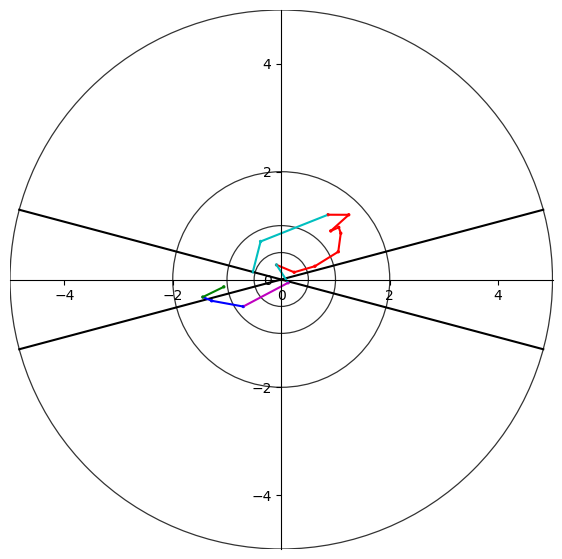

In [13]:
fig, ax = plt.subplots(figsize=(7, 7))
xx = 5*np.cos(15*np.pi/180)
x = np.linspace(-xx, xx, 50)
y1 = x*np.tan(15*np.pi/180)
y2 = x*np.tan(-15*np.pi/180)
ax.plot(x, y1, c='k')
ax.plot(x, y2, c='k')

colors = np.empty((len(r)), dtype='str')
colors[typ==0] = 'r'
colors[typ==1] = 'y'
colors[typ==2] = 'm'
colors[typ==3] = 'b'
colors[typ==4] = 'g'
colors[typ==5] = 'c'
ax.scatter(nino3+nino4, nino3-nino4, s=2, c=colors.tolist())
for i in range(len(r)-1):
    ax.plot(Rp[i:i+2], Ip[i:i+2], c=colors[i])
    
for i in range(5):
    circle = Circle((0, 0), radius=ints_lev[i], fill=False, edgecolor='k', linestyle='-', linewidth=0.9, alpha=0.8)
    ax.add_patch(circle)

ax.spines['left'].set_position('zero')  
ax.spines['bottom'].set_position('zero') 

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')

ax.set_ylim([-5, 5])
ax.set_xlim([-5, 5])

In [151]:
colors

array(['b', 'b', 'm', 'm', 'r', 'r', 'r', 'r', 'r', 'r', 'r', 'r', 'r',
       'r', 'r', 'r', 'r', 'c', 'c', 'c', 'c', 'g', 'g', 'g'], dtype='<U1')

In [63]:
sst_ano.loc[start:end].plot.contourf(col='time', col_wrap=4, cmap='bwr', size=2, aspect=2, levels=21)

TypeError: cannot do slice indexing on DatetimeIndex with these indexers [436] of type int

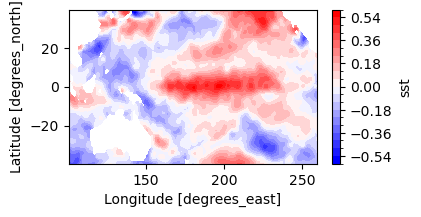

In [91]:
sst_ano.loc['2004-05':'2005-08'].mean(dim='time').plot.contourf(cmap='bwr', size=2, aspect=2, levels=21)

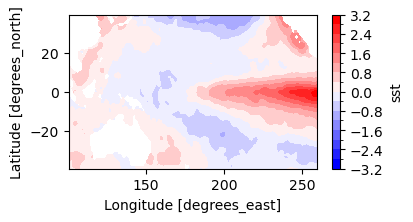

In [93]:
sst_ano.loc['1997-05':'1998-08'].mean(dim='time').plot.contourf(cmap='bwr', size=2, aspect=2, levels=21)

In [198]:
xr.open_dataset('../../data/necp/monthly/uwnd.mon.mean.nc')

<xarray.Dataset>
Dimensions:    (level: 17, lat: 73, lon: 144, time: 552, nbnds: 2)
Coordinates:
  * level      (level) float32 1e+03 925.0 850.0 700.0 ... 50.0 30.0 20.0 10.0
  * lat        (lat) float32 90.0 87.5 85.0 82.5 ... -82.5 -85.0 -87.5 -90.0
  * lon        (lon) float32 0.0 2.5 5.0 7.5 10.0 ... 350.0 352.5 355.0 357.5
  * time       (time) datetime64[ns] 1979-01-01 1979-02-01 ... 2024-12-01
Dimensions without coordinates: nbnds
Data variables:
    time_bnds  (time, nbnds) datetime64[ns] ...
    uwnd       (time, level, lat, lon) float32 ...
Attributes:
    Conventions:    CF-1.0
    title:          Monthly NCEP/DOE Reanalysis 2
    comments:       Data is from \nNCEP/DOE AMIP-II Reanalysis (Reanalysis-2)...
    platform:       Model
    source:         NCEP/DOE AMIP-II Reanalysis (Reanalysis-2) Model
    institution:    National Centers for Environmental Prediction
    dataset_title:  NCEP-DOE AMIP-II Reanalysis
    References:     https://www.psl.noaa.gov/data/gridded/data.ncep.reanalysi...
    source_url:     http://www.cpc.ncep.noaa.gov/products/wesley/reanalysis2/
    history:        created 2002/03 by Hoop (netCDF2.3)\nConverted to chunked...

In [199]:
938/12

78.16666666666667